# Regional fuel price dispersion
Run `python -m src.features.regional` first. Everything below reads parquet files in `data/clean/`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
from src.features import analysis as A, charts
pd.set_option('display.width', 200)
areas, spread, desnz = A.load()

## Average gap to the UK price, by area (pence)

In [2]:
A.gap_table(areas).query("level == 'region'")

,fuel,level,area,mean,sd,low,high
4,E10,region,East Midlands,0.41,0.36,-0.13,1.52
5,E10,region,East of England,0.77,0.29,-0.01,1.41
6,E10,region,London,0.72,0.39,-0.36,1.40
7,E10,region,North East,-1.32,0.37,-2.07,-0.53
8,E10,region,North West,-0.37,0.37,-1.10,0.38
9,E10,region,Northern Ireland,-6.14,1.68,-10.89,-1.73
10,E10,region,Scotland,1.39,0.49,0.46,2.29
11,E10,region,South East,1.48,0.31,0.69,2.16
12,E10,region,South West,0.66,0.33,0.01,1.68
13,E10,region,Wales,-0.54,0.27,-1.34,0.04


## Do gaps widen when prices move?

In [3]:
display(A.spread_by_move(spread))
A.stability(areas, spread).groupby('fuel')[['corr_abs', 'slope']].describe().round(3)

,fuel,weeks,calm_move_p,big_move_p,calm_sd,big_sd,calm_range,big_range,corr_move_sd,sd_over_price_pct
0,E10,36,0.390,3.720,2.094,2.003,7.856,7.523,-0.270,1.307
1,E5,36,0.331,3.635,4.647,4.563,17.721,17.438,-0.274,2.536
2,diesel_premium,36,0.446,5.445,6.234,5.346,23.120,19.921,-0.583,2.912
3,diesel_standard,36,0.557,5.766,2.518,2.132,9.471,8.202,-0.528,1.380


corr_abs                                                  slope                                                 
                   count   mean    std    min    25%    50%    75%    max count   mean    std    min    25%    50%    75%    max
fuel                                                                                                                            
E10                 12.0  0.248  0.153 -0.132  0.189  0.279  0.355  0.403  12.0  0.004  0.027 -0.042 -0.007  0.002  0.010  0.063
E5                  12.0  0.197  0.169 -0.090  0.109  0.185  0.332  0.432  12.0 -0.002  0.019 -0.046 -0.013  0.002  0.007  0.032
diesel_premium      12.0  0.275  0.170  0.060  0.126  0.277  0.409  0.590  12.0  0.008  0.048 -0.035 -0.008  0.001  0.007  0.152
diesel_standard     12.0  0.354  0.216 -0.017  0.234  0.342  0.528  0.635  12.0  0.004  0.023 -0.035 -0.005 -0.002  0.008  0.057

## Weighting: station-weighted vs equal-region UK mean

In [4]:
A.weighting_note(areas)

,fuel,mean,min,max
0,E10,0.33,0.17,0.55
1,E5,1.00,0.73,1.42
2,diesel_premium,1.37,0.76,1.93
3,diesel_standard,0.31,0.07,0.59


## FuelCosts against the DESNZ weekly figure

In [5]:
A.desnz_check(spread, desnz)

,fuelcosts,desnz,weeks,mean_gap_p,sd_gap_p,max_abs_gap_p,corr_levels,corr_weekly_change,first,last
0,E10,unleaded_petrol,41,0.659,1.468,4.313,0.994,0.924,2026-02-09,2026-11-16
1,E5,unleaded_petrol,41,18.095,1.375,21.127,0.995,0.898,2026-02-09,2026-11-16
2,diesel_standard,diesel,41,0.685,2.033,6.663,0.994,0.933,2026-02-09,2026-11-16


## Charts

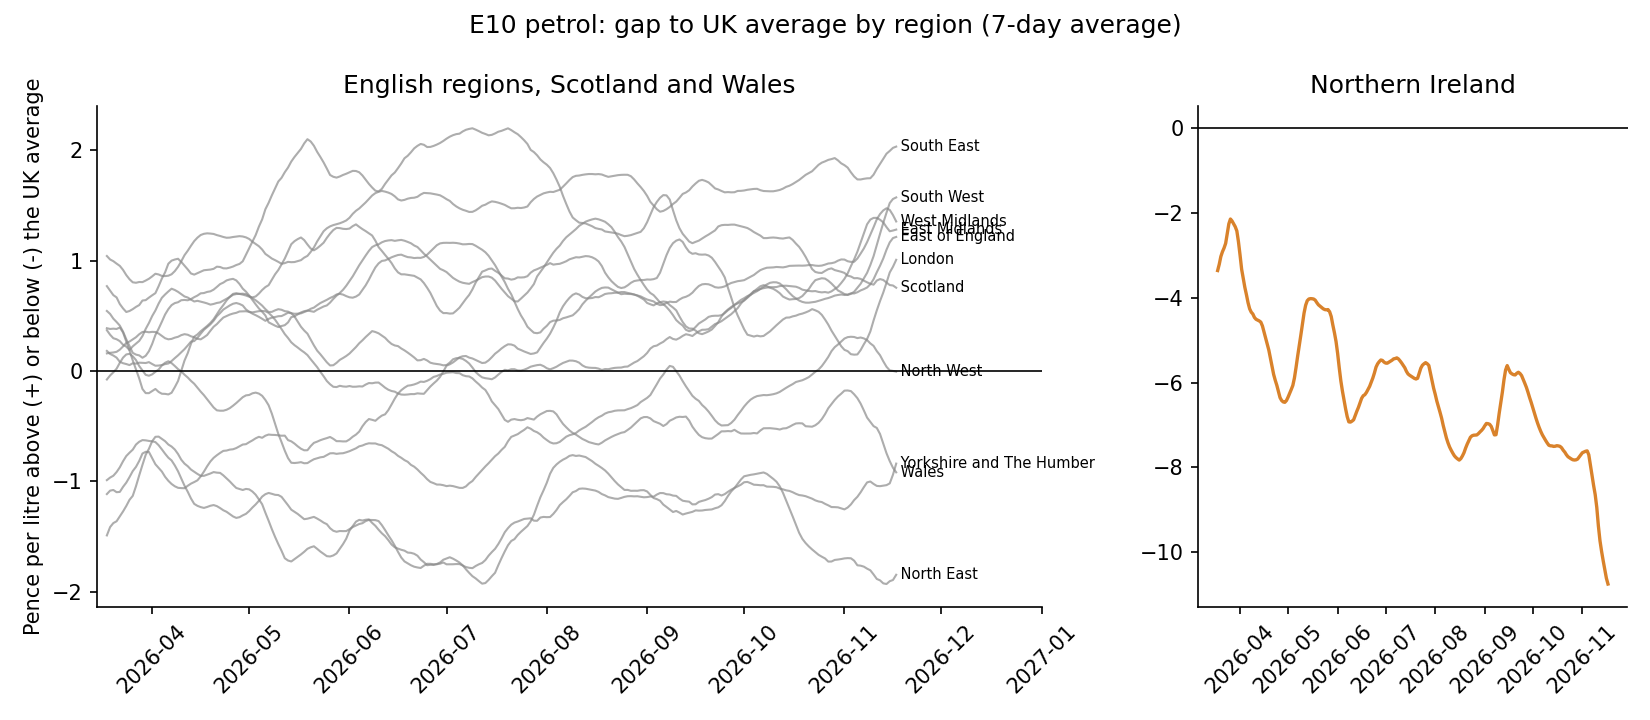

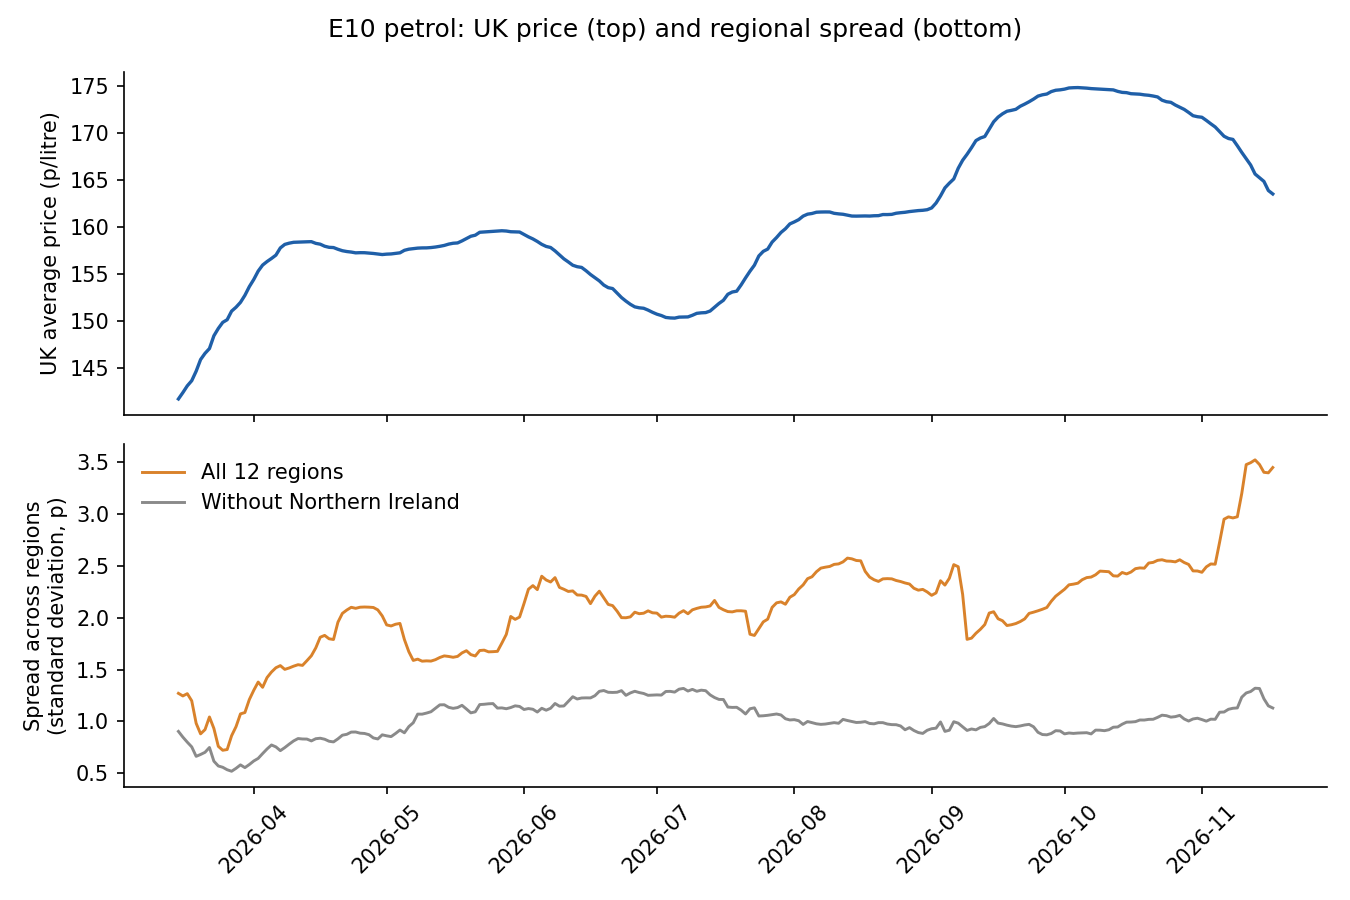

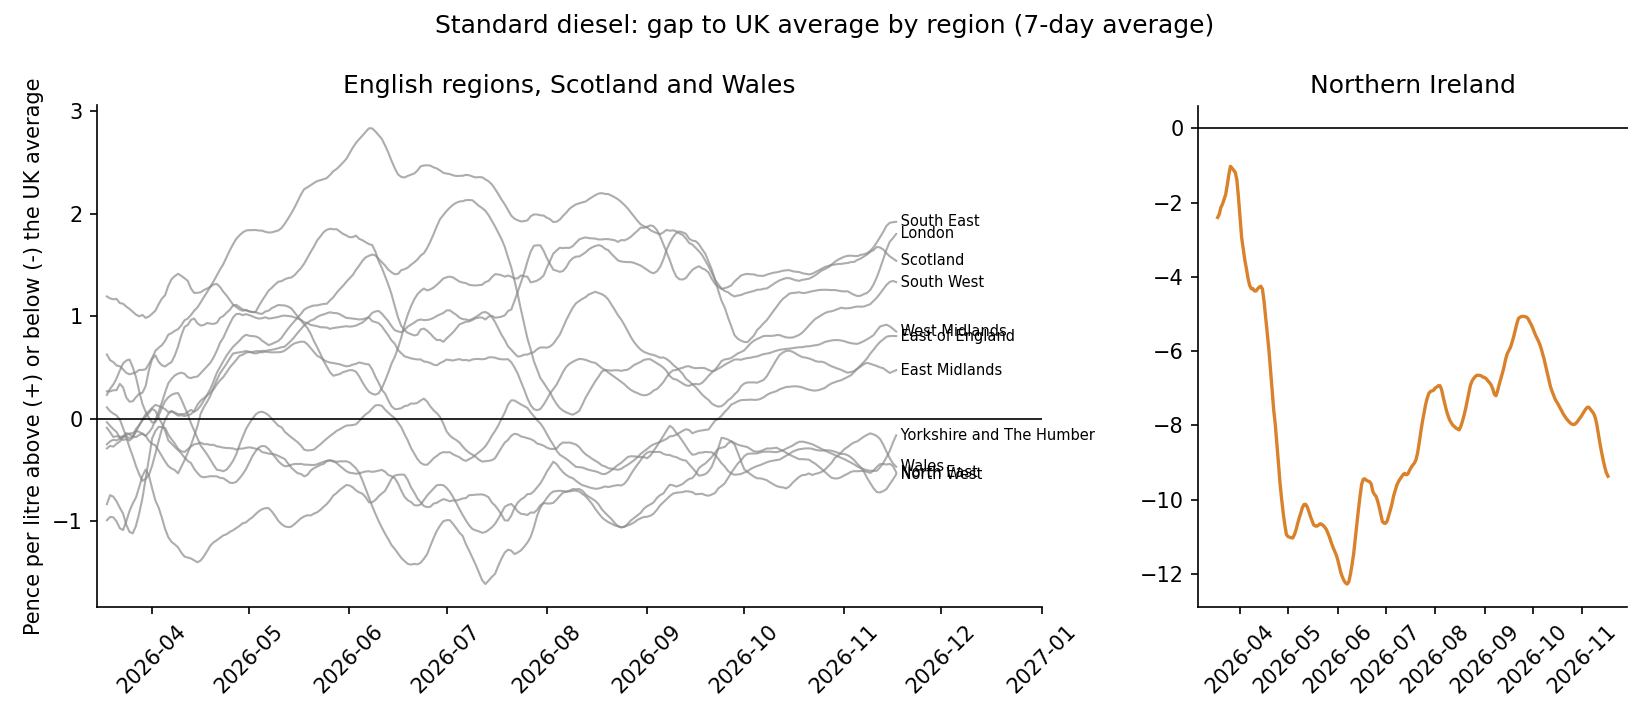

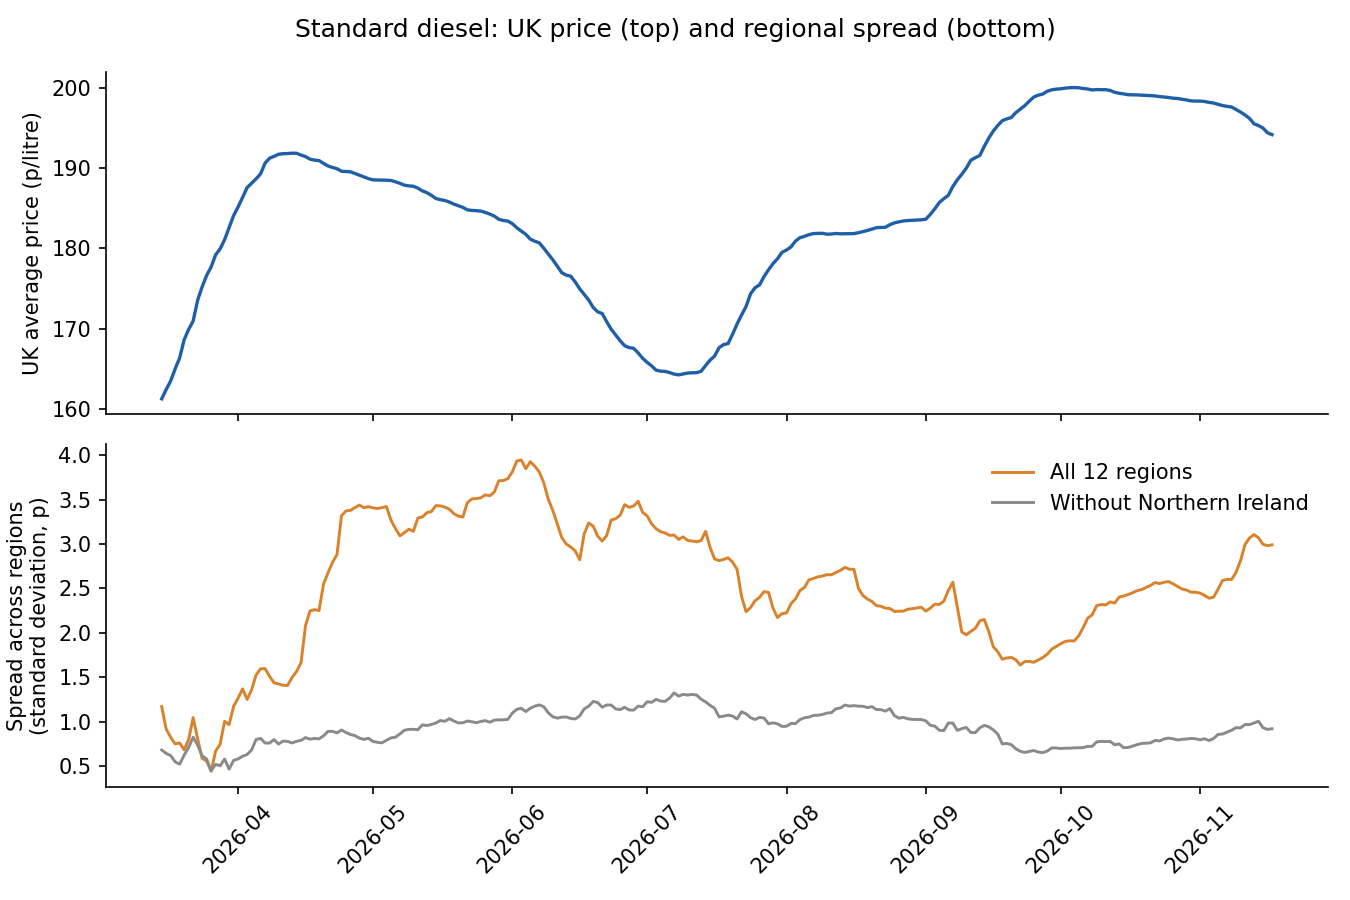

In [6]:
for f in ['E10', 'diesel_standard']:
    display(Image(charts.gap_chart(areas, f)))
    display(Image(charts.spread_chart(areas, spread, f)))